In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

In [4]:
np.random.seed(42)

In [5]:
xy = loadmat ("data/data1.mat")["data1"]
x, y = xy[0], xy[1]
d = loadmat("data/eng_signals.mat")
eng = [d[f"eng_signal{k}"].ravel().astype(float) for k in (1,2,3)]
fs = 500.0
t = np.arange(eng[0].size) / fs

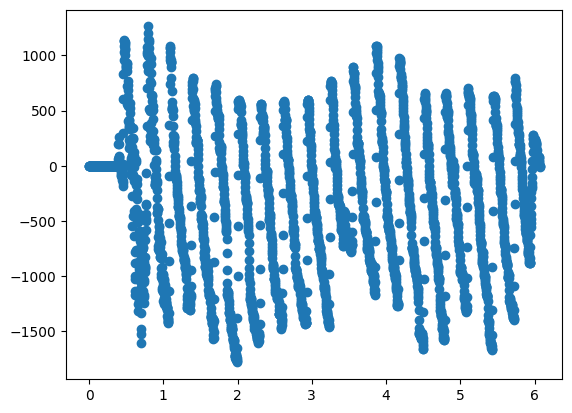

In [6]:
plt.scatter(t, eng[0])

In [12]:
def ransac_line(x, y, residual_threshold, max_trials=1000, random_state=0):
    """Odporne dopasowanie prostej y = a*x + b metodą RANSAC.

    Parameters
    ----------
    x : array-like, shape (n_samples,)
        Jednowymiarowy wektor współrzędnych x (np. czas lub numer próbki).
        Co najmniej dwa punkty i co najmniej dwie różne wartości x.
    y : array-like, shape (n_samples,)
        Jednowymiarowy wektor współrzędnych y, tej samej długości co x.
        Wszystkie wartości x i y muszą być skończonymi liczbami rzeczywistymi.
    residual_threshold : float
        Dodatni, skończony próg zgodności, w jednostkach y.
        Punkt jest zgodny z hipotezą, gdy abs(y_i - (a*x_i + b)) <= próg.
        Jest to reszta pionowa, nie odległość prostopadła do prostej.
    max_trials : int, default=1000
        Dodatnia całkowita liczba prób, łącznie z próbami pominiętymi.
        Wartości logiczne oraz liczby zmiennoprzecinkowe nie są akceptowane.
    random_state : int or None, default=0
        Ziarno lokalnego generatora numpy.random.default_rng.
        Dla tego samego całkowitego ziarna i tych samych danych wynik
        musi być powtarzalny. None oznacza brak ustalonego ziarna.

    Returns
    -------
    a : float
        Nachylenie końcowej prostej dopasowanej metodą OLS do wybranych punktów.
    b : float
        Wyraz wolny końcowej prostej.
    inlier_mask : ndarray of bool, shape (n_samples,)
        Maska najlepszego zbioru konsensusu: True dla punktów zgodnych
        z wybraną hipotezą, False dla pozostałych. Kolejność odpowiada wejściu.
        Maskę zachowujemy SPRZED końcowego OLS; nie klasyfikujemy jej ponownie.

    """
    np.random.seed(random_state)

    rows = []

    for i in range(max_trials):
        r_idx = np.random.choice(range(len(x)), 2, replace=False)
        rx, ry = x[r_idx], y[r_idx]
        if rx[0] != rx[1]:
            print("The same x values! Skipping...")
            continue

        a, b = np.polyfit(rx, ry, 1)
        lx = np.array([x.min(), x.max()])
        ly = a*lx + b

        err = y - (a*x + b)
        plt.scatter(x, err)

        mae = (err**2).mean()

        C_idx = np.abs(err) <= residual_threshold
        C = err[C_idx]

        rows.append({"a": a, "b": b, "C": len(C), "MAE": mae})

    trials = pd.DataFrame(rows)
    trials["index"] = trials.index

    trials_sorted = trials.sort_values(by=["C", "MAE", "index"], ascending=[False, True, True])
    best_row = trials_sorted.iloc[0]
    best_a = best_row["a"]
    best_b = best_row["b"]

    err = y - (best_a*x + best_b)

    C_idx = np.abs(err) <= residual_threshold

    inline_x = x[C_idx]
    inline_y = y[C_idx]

    final_a, final_b = np.polyfit(inline_x, inline_y, 1)

    return final_a, final_b, C_idx

The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same x values! Skipping...
The same

KeyError: 'C'

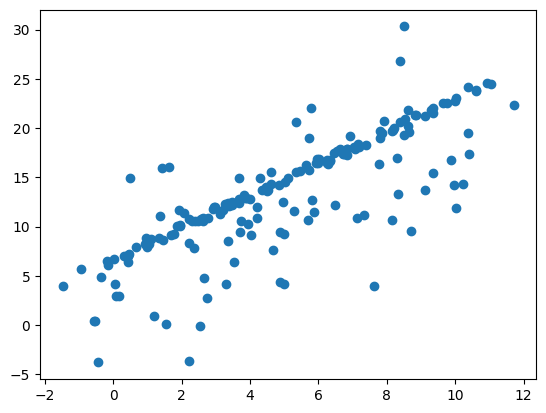

In [11]:
plt.scatter(x, y)
a, b, inlier_mas = ransac_line(x, y, 3.0)